# Part 3D：重新优化的价值（The value of re-optimization）

> 组内工作 notebook。说明文字用中文；**图表、表格的文字用英文**，可以直接放进报告。

## 题目在问什么

2015 年底用**最近 10 年**（2006/01 – 2015/12）的数据重新算一个**只做多最小方差组合**，在 **2016/01 – 2023/07** 这段时间里，和一直沿用 2004 年底那组旧权重的组合比较实际波动率。评述两者的差异，以及为什么这个结果可能符合、也可能不符合预期。

| | 旧组合 | 新组合 |
|---|---|---|
| 确定权重的时点 | 2004/12/31 | 2015/12/31 |
| 估计 $\Sigma$ 用的数据 | 1995/01 – 2004/12 | 2006/01 – 2015/12 |
| 怎么来的 | 直接用 3A 的只做多权重 | 用同样的方法重新优化 |
| 比较区间 | 2016/01 – 2023/07（对两者都是样本外） | 同左 |

**直观理解**：协方差会随时间变化（3C 已经看到相关性从 0.40 升到 0.59）。2004 年的权重反映的是科网泡沫时期的风险结构，到 2016 年已经过时 11 年以上。重新优化相当于"更新地图"。问题是：更新后的地图真的更准吗？

## 本 notebook 额外加的分析（题目没要求）

- **新旧权重对比和换手率**：从旧组合调到新组合要换掉多少仓位，用来解释两者波动差异的来源；
- **分时段检查**：新冠疫情前（2016–2019）和疫情后（2020–2023/07）分别比较。

## 本 notebook 的输出

| 文件 | 内容 |
|---|---|
| `output/tables/tab_3D_weights.csv` | 新旧两组权重及变化 |
| `output/tables/tab_3D_reopt_vol.csv` | 2016–2023 波动率比较（含分时段） |
| `output/figures/fig_3D_reopt_vol.png` | 报告主图：新旧组合波动率对比 |
| `output/figures/fig_3D_weights.png` | 新旧权重对比图 |

## 目录

1. 环境设置 · 2. 读取数据与旧权重 · 3. 重新优化：新组合 · 4. 新旧权重对比与换手率 · 5. 2016–2023 波动率比较 · 6. 分时段检查 · 7. 报告用图表 · 8. 写报告时的要点

## 1. 环境设置

只做多最小方差的求解函数放在 `part3_common.py` 的 `min_var_long_only()` 里，方法与 3A 完全相同（cvxpy + CLARABEL，小于 $10^{-6}$ 的权重归零，并自动检查 KKT 最优性条件）。

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator

HERE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "part3_common.py").exists()
            or (p / "part3" / "python_source" / "part3_common.py").exists())
if not (HERE / "part3_common.py").exists():
    HERE = HERE / "part3" / "python_source"
sys.path.insert(0, str(HERE))
import part3_common as p3
from part3_common import config, utils, CN, EN

config.apply_style()
for k in ["3_seed", "3D_seed", "3D_oos"]:
    print(f"{k:8s}: {config.PERIODS[k]}")

3_seed  : ('1995-01', '2004-12')
3D_seed : ('2006-01', '2015-12')
3D_oos  : ('2016-01', '2023-07')


## 2. 读取数据与旧权重

旧组合直接用 3A 保存的只做多权重。为了确认 `min_var_long_only()` 和 3A 的方法完全一致，先用它在 1995–2004 的数据上重算一次，应当和 3A 的结果相同。

In [2]:
rets = p3.load_industry_returns()
W3A = p3.load_weights_3A()
seed_old = utils.select_period(rets, "3_seed")
seed_new = utils.select_period(rets, "3D_seed")
test = utils.select_period(rets, "3D_oos")

print(f"旧组合估计期: {seed_old.index[0]} ~ {seed_old.index[-1]}，{len(seed_old)} 个月")
print(f"新组合估计期: {seed_new.index[0]} ~ {seed_new.index[-1]}，{len(seed_new)} 个月")
print(f"比较区间    : {test.index[0]} ~ {test.index[-1]}，{len(test)} 个月")
assert len(seed_new) == 120 and len(test) == 91 and seed_new.index.max() < test.index.min()

w_old = W3A["mv_long_only"].rename("old")
diff = (p3.min_var_long_only(seed_old) - w_old).abs().max()
print(f"\n用公共函数重算 2004 年组合，与 3A 权重的最大差异: {diff:.1e}  → 方法一致 ✓")

旧组合估计期: 1995-01 ~ 2004-12，120 个月
新组合估计期: 2006-01 ~ 2015-12，120 个月
比较区间    : 2016-01 ~ 2023-07，91 个月



用公共函数重算 2004 年组合，与 3A 权重的最大差异: 8.7e-16  → 方法一致 ✓


## 3. 重新优化：新组合（截至 2015/12/31）

问题形式与 3A 完全相同，只是 $\Sigma$ 换成用 2006/01 – 2015/12 估计：

$$
\min_{w}\; w^\top \Sigma_{2006\text{–}2015}\, w \qquad \text{s.t.}\quad \textstyle\sum_i w_i = 1,\quad w_i \ge 0
$$

In [3]:
w_new = p3.min_var_long_only(seed_new).rename("new")
print(f"权重合计: {w_new.sum():.6f}；持有行业数: {(w_new > 0).sum()}（旧组合: {(w_old > 0).sum()}）")
print("KKT 最优性条件已在函数内检查通过 ✓\n")
print("新组合持仓：")
for c, v in w_new[w_new > 0].sort_values(ascending=False).items():
    print(f"  {c:6s} {CN[c]:8s} {v:6.1%}")

权重合计: 1.000000；持有行业数: 5（旧组合: 12）
KKT 最优性条件已在函数内检查通过 ✓

新组合持仓：
  Food   食品        37.4%
  Util   公用事业      23.3%
  Beer   啤酒与烈酒     21.2%
  Rtail  零售        13.4%
  Gold   贵金属        4.8%


## 4. 新旧权重对比与换手率

**换手率** = $\tfrac12\sum_i |w_i^{\text{new}} - w_i^{\text{old}}|$，即从旧组合调到新组合需要卖出（同时买入）的仓位比例。0% 表示完全不变，100% 表示完全换成另一批行业。

下表只列出新旧组合中至少一个持有的行业。

In [4]:
cmpw = pd.DataFrame({"old": w_old, "new": w_new})
cmpw["change"] = cmpw["new"] - cmpw["old"]
held = cmpw[(cmpw[["old", "new"]] > 0).any(axis=1)].copy()
held = held.sort_values(["new", "old"], ascending=False)
held.insert(0, "行业", [CN[c] for c in held.index])

turnover = 0.5 * (w_new - w_old).abs().sum()
common = held.index[(held["old"] > 0) & (held["new"] > 0)]
print(f"换手率: {turnover:.1%}")
print(f"两组都持有的行业: {len(common)} 个（{'、'.join(CN[c] for c in common)}）")
print(f"只在旧组合中: {((held['old'] > 0) & (held['new'] == 0)).sum()} 个；只在新组合中: {((held['old'] == 0) & (held['new'] > 0)).sum()} 个")

out = held.drop(columns="行业").rename(columns={"old": "Old weights (as of Dec 2004)",
                                                "new": "New weights (as of Dec 2015)",
                                                "change": "Change"})
out.insert(0, "Industry", [EN[c] for c in out.index])
out.index.name = "Code"
print("\nCSV →", utils.save_table(out, "tab_3D_weights", float_format="%.6f").relative_to(p3.ROOT))
held.style.format({"old": "{:.1%}", "new": "{:.1%}", "change": "{:+.1%}"})

换手率: 73.5%
两组都持有的行业: 3 个（食品、公用事业、贵金属）
只在旧组合中: 9 个；只在新组合中: 2 个

CSV → output/tables/tab_3D_weights.csv


,行业,old,new,change
Food,食品,9.1%,37.4%,+28.3%
Util,公用事业,16.7%,23.3%,+6.6%
Beer,啤酒与烈酒,0.0%,21.2%,+21.2%
Rtail,零售,0.0%,13.4%,+13.4%
Gold,贵金属,0.7%,4.8%,+4.0%
RlEst,房地产,13.7%,0.0%,-13.7%
Hshld,日用消费品,12.3%,0.0%,-12.3%
Agric,农业,10.7%,0.0%,-10.7%
Drugs,制药,9.5%,0.0%,-9.5%
Guns,国防军工,9.3%,0.0%,-9.3%


### 4.1 旧权重在新估计期里已经"过时"了多少

站在 2015 年底回头看：如果 2006–2015 一直拿着旧组合，它在这 10 年的波动率是多少？与新组合在同一时期（新组合的样本内）对比，可以看出旧权重和最新的风险结构偏离得有多远。

In [5]:
pf = lambda w, df: df[w.index] @ w
v_old_0615 = utils.annualized_volatility(pf(w_old, seed_new))
v_new_0615 = utils.annualized_volatility(pf(w_new, seed_new))
print(f"2006–2015：旧组合 {v_old_0615:.1%}，新组合（样本内）{v_new_0615:.1%}")

2006–2015：旧组合 14.7%，新组合（样本内）10.3%


## 5. 2016/01 – 2023/07 波动率比较（题目要的核心数字）

两个组合在这段时间都是**样本外**，计算方法与 3C 相同（权重固定、每月调回目标权重、年化波动率 = 月收益标准差 × √12）。参照组照例是 49 个行业等权组合，不想放的话把 `SHOW_REFERENCE` 改成 `False`。

In [6]:
SHOW_REFERENCE = True

r_old, r_new, r_ew = pf(w_old, test), pf(w_new, test), test.mean(axis=1)
v_old, v_new, v_ew = (utils.annualized_volatility(x) for x in (r_old, r_new, r_ew))
print(f"旧组合（2004 年权重）: {v_old:.2%}")
print(f"新组合（2015 年权重）: {v_new:.2%}")
print(f"差异（新 − 旧）      : {v_new - v_old:+.2%}，相对降低 {1 - v_new / v_old:.0%}")
print(f"参照：等权 49 个行业  : {v_ew:.2%}")
print(f"\n新组合 样本外 / 样本内 = {v_new:.1%} / {v_new_0615:.1%} = ×{v_new / v_new_0615:.2f}")

旧组合（2004 年权重）: 14.52%
新组合（2015 年权重）: 12.81%
差异（新 − 旧）      : -1.71%，相对降低 12%
参照：等权 49 个行业  : 17.82%

新组合 样本外 / 样本内 = 12.8% / 10.3% = ×1.24


## 6. 分时段检查

比较区间里有新冠疫情。把它切成**疫情前（2016–2019）**和**疫情后（2020–2023/07）**两段，看新组合的优势是不是一直存在，还是主要来自疫情冲击。

疫情最剧烈的 2020/02–03 只有两个月，算标准差没有意义，所以这一段改为比较**累计收益**（这也是 3E 会用到的危机区间）。

In [7]:
SUB = {"Full: Jan 2016 - Jul 2023": ("2016-01", "2023-07"),
       "Pre-COVID: 2016 - 2019": ("2016-01", "2019-12"),
       "COVID and after: 2020 - Jul 2023": ("2020-01", "2023-07")}
rows = {}
for name, (a, b) in SUB.items():
    rows[name] = {k: utils.annualized_volatility(r.loc[a:b]) for k, r in
                  [("Old (Dec 2004 weights)", r_old), ("New (Dec 2015 weights)", r_new), ("Equal weight (49 industries)", r_ew)]}
vol_tab = pd.DataFrame(rows).T
vol_tab["New − Old"] = vol_tab["New (Dec 2015 weights)"] - vol_tab["Old (Dec 2004 weights)"]
vol_tab.index.name = "Period (annualized volatility)"
print("CSV →", utils.save_table(vol_tab, "tab_3D_reopt_vol", float_format="%.6f").relative_to(p3.ROOT))

covid = {k: (1 + r.loc["2020-02":"2020-03"]).prod() - 1 for k, r in
         [("旧组合", r_old), ("新组合", r_new), ("等权", r_ew)]}
print("\n2020/02–03 新冠冲击期间累计收益：" + "，".join(f"{k} {v:.1%}" for k, v in covid.items()))
vol_tab.style.format("{:.2%}").format("{:+.2%}", subset=["New − Old"])

CSV → output/tables/tab_3D_reopt_vol.csv

2020/02–03 新冠冲击期间累计收益：旧组合 -21.2%，新组合 -15.1%，等权 -24.6%


,Old (Dec 2004 weights),New (Dec 2015 weights),Equal weight (49 industries),New − Old
Period (annualized volatility),,,,
Full: Jan 2016 - Jul 2023,14.52%,12.81%,17.82%,-1.71%
Pre-COVID: 2016 - 2019,10.79%,10.31%,12.87%,-0.47%
COVID and after: 2020 - Jul 2023,17.93%,15.25%,22.25%,-2.68%


## 7. 报告用图表

### 7.1 主图：新旧组合在 2016–2023 的波动率

三组柱子分别对应全区间、疫情前、疫情后。颜色：**旧组合 = 浅橙**（与 3A–3C 中只做多组合同色系），**新组合 = 深橙**，等权参照 = 灰色。

PNG → output/figures/fig_3D_reopt_vol.png


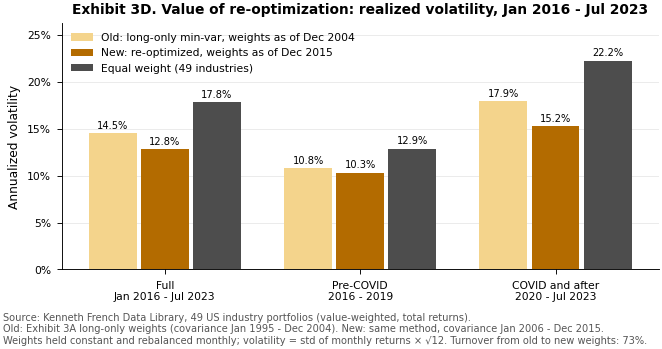

In [8]:
OLD_C = mcolors.to_hex(0.45 * np.array(mcolors.to_rgb(p3.PF_COLORS["mv_long_only"])) + 0.55)
NEW_C = "#B36B00"
series = [("Old: long-only min-var, weights as of Dec 2004", "Old (Dec 2004 weights)", OLD_C),
          ("New: re-optimized, weights as of Dec 2015", "New (Dec 2015 weights)", NEW_C)]
if SHOW_REFERENCE:
    series.append(("Equal weight (49 industries)", "Equal weight (49 industries)", config.COLOR_MARKET))

fig, ax = utils.new_fig("full")
x = np.arange(len(vol_tab))
bw = 0.8 / len(series)
for i, (label, col, colr) in enumerate(series):
    pos = x - 0.4 + bw * (i + 0.5)
    ax.bar(pos, vol_tab[col], width=bw * 0.92, color=colr, label=label)
    for p, v in zip(pos, vol_tab[col]):
        ax.text(p, v + 0.003, f"{v:.1%}", ha="center", va="bottom", fontsize=config.FONT_SMALL - 0.5)
ax.set_xticks(x, [s.replace(": ", "\n") for s in vol_tab.index])
utils.percent_axis(ax, "y")
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.set_ylim(0, vol_tab[[c for _, c, _ in series]].to_numpy().max() * 1.18)
ax.set_ylabel("Annualized volatility")
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
ax.legend(loc="upper left")
ax.set_title("Exhibit 3D. Value of re-optimization: realized volatility, Jan 2016 - Jul 2023")
src = (p3.SOURCE_FF49 + "\nOld: Exhibit 3A long-only weights (covariance Jan 1995 - Dec 2004). New: same method, covariance "
       "Jan 2006 - Dec 2015.\nWeights held constant and rebalanced monthly; volatility = std of monthly returns × √12. "
       f"Turnover from old to new weights: {turnover:.0%}.")
print("PNG →", utils.save_fig(fig, "fig_3D_reopt_vol", source=src).relative_to(p3.ROOT))
plt.show()

### 7.2 新旧权重对比图

只列出新旧组合中至少一个持有的行业。从图上可以直接看到：重新优化不是"微调"，而是换了一大批行业。

PNG → output/figures/fig_3D_weights.png


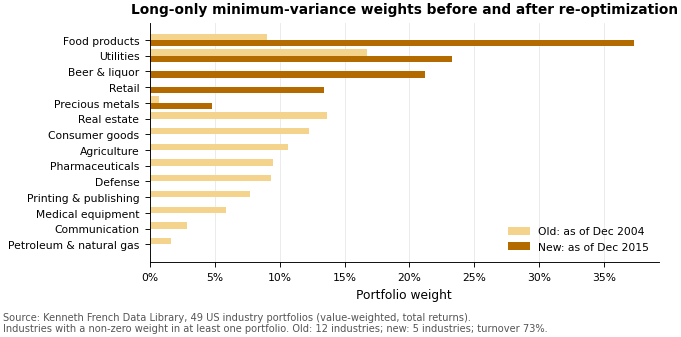

In [9]:
plot_df = held.iloc[::-1]
fig, ax = utils.new_fig("full")
y = np.arange(len(plot_df))
h = 0.4
ax.barh(y + h / 2, plot_df["old"], height=h, color=OLD_C, label="Old: as of Dec 2004")
ax.barh(y - h / 2, plot_df["new"], height=h, color=NEW_C, label="New: as of Dec 2015")
ax.set_yticks(y, [EN[c] for c in plot_df.index])
utils.percent_axis(ax, "x")
ax.xaxis.set_major_locator(MultipleLocator(0.05))
ax.set_xlabel("Portfolio weight")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.legend(loc="lower right")
ax.set_title("Long-only minimum-variance weights before and after re-optimization")
src = (p3.SOURCE_FF49 + "\nIndustries with a non-zero weight in at least one portfolio. "
       f"Old: {(w_old > 0).sum()} industries; new: {(w_new > 0).sum()} industries; turnover {turnover:.0%}.")
print("PNG →", utils.save_fig(fig, "fig_3D_weights", source=src).relative_to(p3.ROOT))
plt.show()

## 8. 写报告时的要点

> 下面的数字来自本 notebook 的运行结果（数据固定，重跑结果不变）。

### 结果速览

| 2016/01 – 2023/07 年化波动率 | 旧组合（2004 年权重） | 新组合（2015 年权重） | 新 − 旧 | 等权 49 个行业（参照） |
|---|---|---|---|---|
| 全区间 | 14.5% | **12.8%** | −1.7 个百分点（相对 −12%） | 17.8% |
| 疫情前 2016–2019 | 10.8% | 10.3% | −0.5 | 12.9% |
| 疫情后 2020–2023/07 | 17.9% | 15.2% | −2.7 | 22.2% |
| 2020/02–03 累计收益 | −21.2% | −15.1% | +6.1 | −24.6% |

| 权重变化 | |
|---|---|
| 持有行业数 | 旧 12 个 → 新 **5 个** |
| 两组都持有 | 3 个：食品、公用事业、贵金属 |
| 换手率 | **73.5%** |
| 新组合持仓 | 食品 37.4%、公用事业 23.3%、啤酒与烈酒 21.2%、零售 13.4%、贵金属 4.8% |

### 可以写进报告的观察

1. **重新优化确实降低了风险，符合预期**：新组合在 2016–2023 的波动率为 12.8%，比沿用 2004 年权重的旧组合（14.5%）低 1.7 个百分点，相对降低约 12%。两者都明显低于等权组合（17.8%）。
2. **原因：协方差是随时间变化的，越新的估计越贴近未来**。站在 2015 年底看，旧权重已经明显过时：如果 2006–2015 一直持有旧组合，波动率是 14.7%，而按当时数据优化的新组合只有 10.3%。新数据反映了金融危机后的风险结构，比如**房地产**在旧组合里有 13.7%，但它在 2008 年危机中暴跌，新组合把它完全剔除了。
3. **但优势主要来自疫情期间，平时差别不大**：
    - 疫情前（2016–2019）两者只差 0.5 个百分点，几乎一样；
    - 疫情后（2020–2023/07）差 2.7 个百分点；
    - 2020/02–03 疫情冲击中，新组合累计跌 15.1%，旧组合跌 21.2%。
   
   也就是说，"重新优化的价值"高度依赖于是否碰上了一次危机，而且新组合偏重的食品、公用事业、零售（日常必需品零售）恰好在疫情期间相对抗跌。这一点有运气成分，不能保证每次重新优化都有这么大的改善。
4. **为什么结果"可能不符合预期"（题目的另一半）**：
    - **估计误差依然存在**：新组合同样只用 120 个月估计 49×49 矩阵。它的样本外/样本内比值是 ×1.24（10.3% → 12.8%），说明仍有"水分"；
    - **重新优化会拟合新的噪音**：73.5% 的换手率说明这不是微调，而是换了一大批行业。如果新的估计期碰巧有特殊事件（这里是 2008 年金融危机），权重就会偏向那次危机中的"赢家"，未来不一定适用；
    - **集中度上升**：新组合只持有 5 个行业，食品一个行业就占 37.4%。单一行业的特殊冲击（如食品安全事件、监管变化）会对组合造成很大影响，这种风险用历史协方差是看不出来的；
    - **成本没有计入**：73.5% 的换手在现实中会产生交易成本，会抵消一部分降风险的好处。
5. **实务上的启示**：与其很多年才重新优化一次，不如定期（例如每年或每季度）用滚动窗口重新估计，同时用换手限制、权重上限或协方差收缩（shrinkage）来控制噪音和集中度。这一点可以作为结论里的延伸讨论。

### 英文写法参考（可改写进报告）

> Re-optimizing the long-only minimum-variance portfolio at end-2015 with the most recent ten years of data (Jan 2006 – Dec 2015) lowered realized volatility over Jan 2016 – Jul 2023 from 14.5% to 12.8% p.a. (−12% in relative terms), compared with 17.8% for an equally weighted portfolio. This is in line with expectations: covariances are not stable over time, and by 2015 the 2004 weights were stale. Over 2006–2015 the old portfolio had a volatility of 14.7%, versus 10.3% for the re-optimized one. The improvement is, however, concentrated in the COVID period: before 2020 the two portfolios had almost identical volatility (10.3% vs 10.8%), while in Feb–Mar 2020 the new portfolio lost 15.1% versus 21.2% for the old one. Re-optimization is not a free lunch: turnover was 73.5% (ignoring transaction costs), the new portfolio holds only five industries (37% in Food), and its out-of-sample volatility was still 24% above its in-sample estimate, showing that estimation error remains.

### 备注

- 参照组（等权）不是题目要求的；不想放的话把第 5 节的 `SHOW_REFERENCE` 改成 `False` 再重跑；
- 新旧权重对比图（`fig_3D_weights.png`）和换手率是额外分析，放不放进报告由你决定。如果篇幅紧张，可以只在正文里用一句话提一下换手率和持仓变化。